# Online Shoppers: Will a Session End in a Purchase?

**Data:** [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), with 12,330 browsing sessions.
**Target:** `Revenue` (1 = the session ended in a purchase, about 15% of sessions).

We train **logistic regression**, a **linear SVM**, a **polynomial SVM** and an **RBF SVM**, pick the best one by F1 score, and show its confusion matrix the logistic regression coefficients, and each model's decision boundary.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Load and explore the data

In [2]:
df = pd.read_csv("data/online_shoppers_intention.csv")
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

print(df.shape)
print("Purchase rate:", round(df["Revenue"].mean(), 3))
df.head()

(12330, 18)
Purchase rate: 0.155


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


Only about 15% of sessions end in a purchase. A model that always says "no purchase" would be about 85% accurate, so accuracy alone is misleading.
We therefore also look at **ROC AUC** (how well the model ranks buyers above non-buyers), **recall** (the share of buyers we catch) and **precision** (the share of predicted buyers who really buy).

In [3]:
num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

# Average of each numeric feature for buyers vs non-buyers
df.groupby("Revenue")[num_cols].mean().T.round(2)

Revenue,0,1
Administrative,2.12,3.39
Administrative_Duration,73.74,119.48
Informational,0.45,0.79
Informational_Duration,30.24,57.61
ProductRelated,28.71,48.21
ProductRelated_Duration,1069.99,1876.21
BounceRates,0.03,0.01
ExitRates,0.05,0.02
PageValues,1.98,27.26
SpecialDay,0.07,0.02


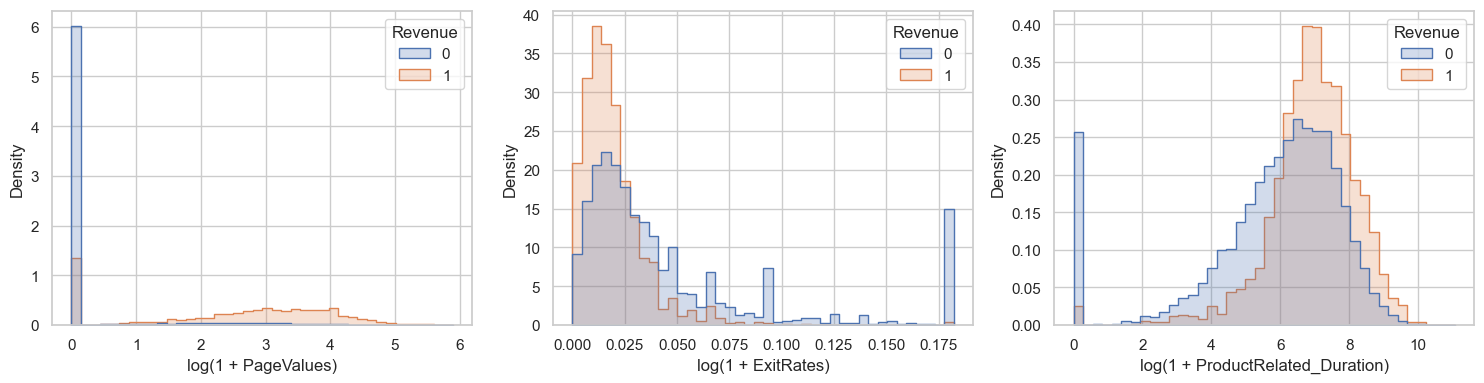

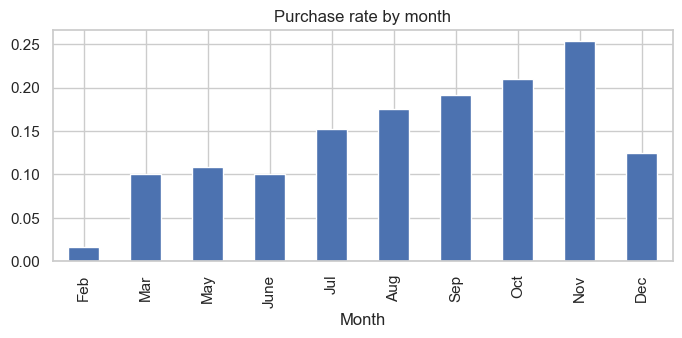

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.histplot(x=np.log1p(df[col]), hue=df["Revenue"], stat="density", common_norm=False, bins=40, element="step", ax=ax)
    ax.set_xlabel(f"log(1 + {col})")
plt.tight_layout(); plt.show()

month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df.groupby("Month")["Revenue"].mean().reindex(month_order).plot.bar(figsize=(8, 3), title="Purchase rate by month")
plt.show()

Buyers have much higher *PageValues* and lower *ExitRates*. November has the highest purchase rate.

## 2. Preprocessing and train/test split
- Numeric features are very skewed, so we apply `log(1 + x)` and then standardize them. Both SVMs and regularized logistic regression need features on the same scale.
- *Month* and *VisitorType* are one-hot encoded, and *Weekend* is already 0/1.
- *OperatingSystems*, *Browser*, *Region* and *TrafficType* are ID codes with no numeric meaning, so we leave them out.
- We use an 80/20 split that keeps the 15% purchase rate in both parts. Tuning uses 5-fold cross-validation on the training set only.

In [5]:
log_cols = [c for c in num_cols if c != "SpecialDay"]
features = num_cols + ["Month", "VisitorType", "Weekend"]

preprocess = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), log_cols),
    ("scale", StandardScaler(), ["SpecialDay"]),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), ["Month", "VisitorType"]),
    ("keep", "passthrough", ["Weekend"]),
], verbose_feature_names_out=False)

X, y = df[features], df["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print("train:", X_train.shape, " test:", X_test.shape)

train: (9864, 13)  test: (2466, 13)


## 3. Train and compare the models
Each model is tuned with a grid search (5-fold CV, scored by ROC AUC). We train each model twice: once with `class_weight=None` and once with `class_weight="balanced"`. We also record how long fitting and predicting take.

In [6]:
models = {
    "Logistic regression": (LogisticRegression(max_iter=5000), {"C": [0.01, 0.1, 1, 10]}),
    "Linear SVM":          (LinearSVC(max_iter=20000),         {"C": [0.01, 0.1, 1]}),
    "Polynomial SVM":      (SVC(kernel="poly", coef0=1),        {"degree": [2, 3], "C": [0.1, 1, 10]}),
    "RBF SVM":             (SVC(kernel="rbf"),                  {"C": [1, 10, 100], "gamma": [0.003, 0.01, 0.03]}),
}

results, best_models = [], {}
for cw in [None, "balanced"]:
    for name, (model, grid) in models.items():
        pipe = make_pipeline(preprocess, model.set_params(class_weight=cw))
        grid = {f"{pipe.steps[-1][0]}__{k}": v for k, v in grid.items()}   # e.g. "svc__C"
        search = GridSearchCV(pipe, grid, cv=5, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
        best = search.best_estimator_

        start = time.perf_counter(); best.fit(X_train, y_train); fit_time = time.perf_counter() - start
        start = time.perf_counter(); pred = best.predict(X_test); predict_time = time.perf_counter() - start

        results.append({
            "model": name, "class_weight": str(cw),
            "best params": {k.split("__")[1]: v for k, v in search.best_params_.items()},
            "train AUC": roc_auc_score(y_train, best.decision_function(X_train)),
            "CV AUC": search.best_score_,
            "test AUC": roc_auc_score(y_test, best.decision_function(X_test)),
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "fit (s)": fit_time, "predict (ms)": predict_time * 1000,
        })
        best_models[(name, str(cw))] = best

results = pd.DataFrame(results)
results.to_csv("model_results.csv", index=False)
results.round(3)

,model,class_weight,best params,train AUC,CV AUC,test AUC,accuracy,precision,recall,F1,fit (s),predict (ms)
0,Logistic regression,None,{'C': 1},0.916,0.915,0.919,0.899,0.719,0.568,0.635,0.092,13.554
1,Linear SVM,None,{'C': 0.1},0.915,0.914,0.919,0.893,0.684,0.579,0.627,0.095,14.018
2,Polynomial SVM,None,"{'C': 10, 'degree': 2}",0.925,0.916,0.906,0.896,0.699,0.579,0.633,4.472,255.347
3,RBF SVM,None,"{'C': 100, 'gamma': 0.01}",0.927,0.912,0.904,0.897,0.703,0.576,0.633,3.837,794.473
4,Logistic regression,balanced,{'C': 1},0.921,0.919,0.924,0.870,0.556,0.809,0.659,0.085,12.183
5,Linear SVM,balanced,{'C': 0.1},0.921,0.919,0.924,0.881,0.587,0.788,0.673,0.085,16.685
6,Polynomial SVM,balanced,"{'C': 1, 'degree': 2}",0.935,0.927,0.925,0.871,0.556,0.827,0.665,3.365,387.602
7,RBF SVM,balanced,"{'C': 10, 'gamma': 0.01}",0.933,0.927,0.925,0.871,0.558,0.822,0.665,4.249,1255.689


## 4. Best model (highest F1 score)

Best model: Linear SVM (class_weight=balanced), F1 = 0.673


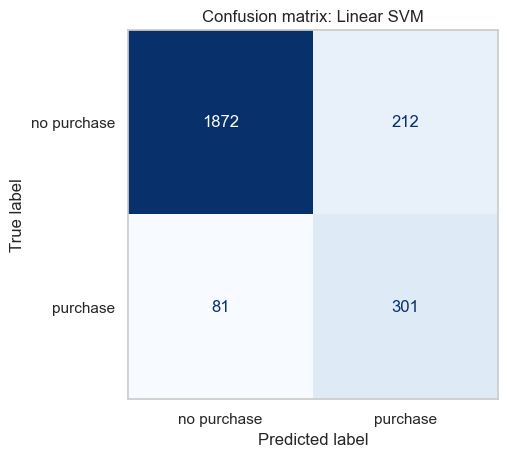

In [7]:
best = results.loc[results["F1"].idxmax()]
print(f"Best model: {best['model']} (class_weight={best['class_weight']}), F1 = {best['F1']:.3f}")

ConfusionMatrixDisplay.from_estimator(best_models[(best["model"], best["class_weight"])], X_test, y_test,
                                      display_labels=["no purchase", "purchase"], colorbar=False, cmap="Blues")
plt.grid(False)
plt.title(f"Confusion matrix: {best['model']}")
plt.show()

## 5. Logistic regression coefficients
Positive bars raise the chance of a purchase, and negative bars lower it.

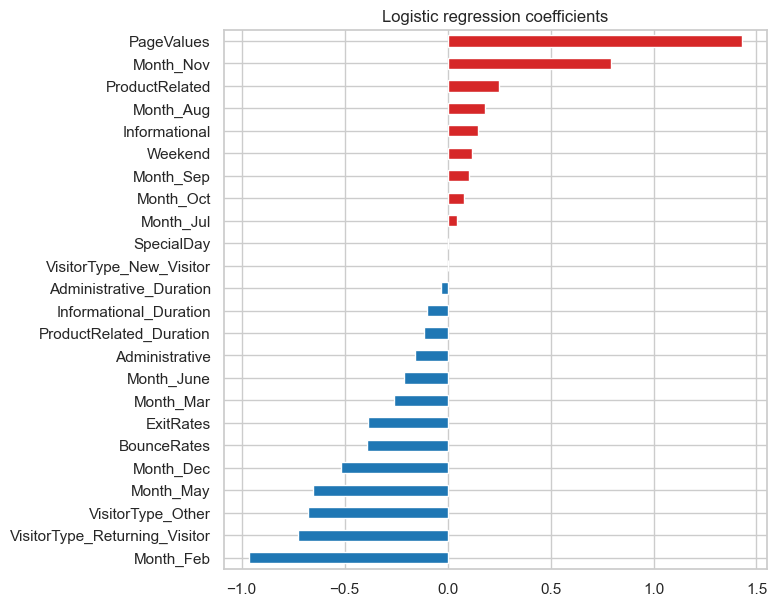

In [8]:
lr = best_models[("Logistic regression", "None")]
coefs = pd.Series(lr[-1].coef_[0], index=lr[0].get_feature_names_out()).sort_values()

coefs.plot.barh(figsize=(7, 7), color=np.where(coefs > 0, "tab:red", "tab:blue"), title="Logistic regression coefficients")
plt.show()

## 6. Decision boundaries
Each model is trained on just two features, **PageValues** and **ExitRates**, so that its decision boundary can be drawn. The black line is the boundary, and the red region is where the model predicts a purchase (`class_weight="balanced"`).

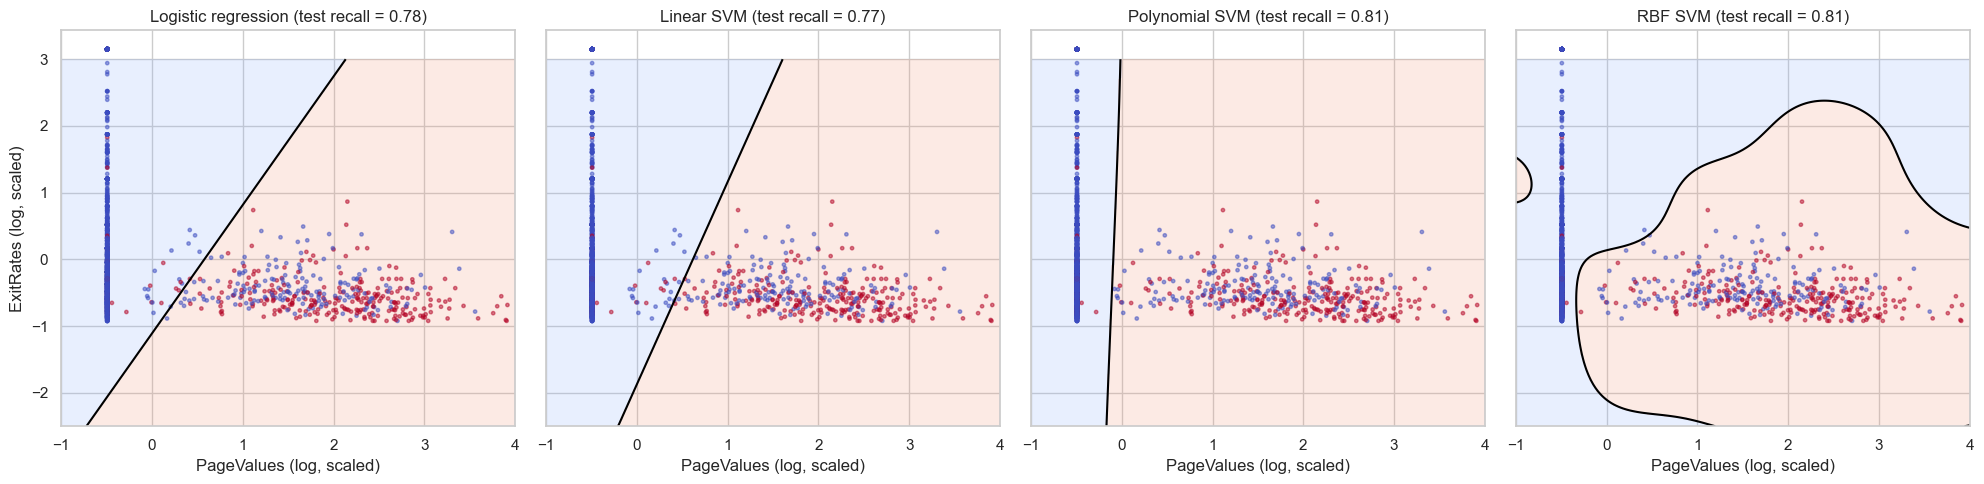

In [9]:
scaler = make_pipeline(FunctionTransformer(np.log1p), StandardScaler())
Z_train = scaler.fit_transform(X_train[["PageValues", "ExitRates"]])
Z_test = scaler.transform(X_test[["PageValues", "ExitRates"]])

xx, yy = np.meshgrid(np.linspace(-1, 4, 200), np.linspace(-2.5, 3, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

models_2d = {"Logistic regression": LogisticRegression(class_weight="balanced"),
             "Linear SVM": LinearSVC(class_weight="balanced"),
             "Polynomial SVM": SVC(kernel="poly", degree=3, coef0=1, class_weight="balanced"),
             "RBF SVM": SVC(kernel="rbf", C=10, gamma=1, class_weight="balanced")}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, (name, m) in zip(axes, models_2d.items()):
    m.fit(Z_train, y_train)
    zz = m.decision_function(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0, alpha=0.2, cmap="coolwarm")
    ax.contour(xx, yy, zz, levels=[0], colors="black")
    ax.scatter(Z_train[:2000, 0], Z_train[:2000, 1], c=y_train.iloc[:2000], cmap="coolwarm", s=6, alpha=0.5)
    ax.set_title(f"{name} (test recall = {recall_score(y_test, m.predict(Z_test)):.2f})")
    ax.set_xlabel("PageValues (log, scaled)")
axes[0].set_ylabel("ExitRates (log, scaled)")
plt.tight_layout(); plt.show()